# Priorização de vulnerabilidades orientada a risco

Protótipo do Projeto de Aplicação (Pós-Graduação em IA e Cibersegurança, PUCPR Digital). Autora: Mylena Ferreira Torres.

O notebook reproduz o experimento do artigo com dados públicos da NVD, do catálogo KEV (CISA) e do EPSS (FIRST). As saídas abaixo já estão gravadas, então é possível ler os resultados sem executar nada. Para executar, abra no Google Colab e use *Ambiente de execução > Executar tudo*.

## 0. Preparação

No Colab, esta célula baixa o repositório. Em uma cópia local, ela não faz nada.

In [1]:
import os, sys
if not os.path.exists('analise.py'):
    os.system('git clone -q https://github.com/torresmylena-arch/priorizacao-vulnerabilidades-risco.git')
    os.chdir('priorizacao-vulnerabilidades-risco')
sys.path.insert(0, os.getcwd())
print('pasta de trabalho pronta:', os.path.exists('analise.py'))

pasta de trabalho pronta: True


## 1. Carga dos dados e auditoria temporal

Cada CVE recebe uma data de decisão `t_d` (primeiro ciclo mensal após a publicação). Os atributos são reconstruídos como estavam nessa data, e a função `auditar` falha se algum deles tiver data posterior.

In [2]:
import json, numpy as np, pandas as pd
import analise as A

base, kev, epss = A.carregar('dados')
tr, est_tr, excl_tr = A.montar_conjunto(base, A.TREINO_INI, A.TREINO_FIM)
te, est_te, excl_te = A.montar_conjunto(base, A.TESTE_INI, A.TESTE_FIM)
print('Treino (2023):', len(tr), 'CVEs,', int(tr['y'].sum()), 'entraram no KEV em até 365 dias')
print('Teste  (2025):', len(te), 'CVEs,', int(te['y'].sum()), 'entraram no KEV em até 365 dias')
print('Atributos com data posterior à decisão, treino:', A.auditar(tr, est_tr, tr['t_d']))
print('Atributos com data posterior à decisão, teste: ', A.auditar(te, est_te, te['t_d']))
print('Origem dos atributos no teste:', est_te['fonte'].value_counts().to_dict())

Treino (2023): 23250 CVEs, 53 entraram no KEV em até 365 dias
Teste  (2025): 30949 CVEs, 58 entraram no KEV em até 365 dias
Atributos com data posterior à decisão, treino: 0
Atributos com data posterior à decisão, teste:  0
Origem dos atributos no teste: {'cna': 26917, 'nvd': 4032}


## 2. Probabilidade de exploração

As variantes são treinadas e calibradas com dados de 2023 e avaliadas nas CVEs de 2025. A segunda rodada (S1, S2 e S3) usa sinais abertos e datados: EPSS, histórico do fabricante no KEV e provas de conceito públicas. A variante final é escolhida na validação (setembro a dezembro de 2023), sem contato com o teste.

In [3]:
from sklearn.metrics import average_precision_score
ep_tr = A.epss_em(epss, tr['cve'], tr['t_d']); ep_te = A.epss_em(epss, te['cve'], te['t_d'])
mod = A.treinar(tr, est_tr, ep_tr, A.carregar_sinais('dados', kev))
y = te['y'].values
linhas = []
for k, v in mod['variantes'].items():
    s = A.prever(mod, te, est_te, k, ep_te, te['t_d'])
    linhas.append({'variante': k, 'AP validação': round(v['ap_val'], 4), 'AP teste': round(average_precision_score(y, s), 4),
                   'revocação no 1%': round(A.prec_rec_at_k(y, s, 0.01)[1], 3)})
print(pd.DataFrame(linhas).to_string(index=False))
print('\nVariante escolhida na validação:', mod['final'])
print('Prevalência no teste (acaso):', round(float(y.mean()), 4))

variante  AP validação  AP teste  revocação no 1%
 lr_meta        0.0058    0.0034            0.052
hgb_meta        0.0045    0.0028            0.017
 lr_epss        0.0085    0.0043            0.034
hgb_epss        0.0601    0.0095            0.052
epss_cal        0.0644    0.0422            0.207
      S1        0.0977    0.0943            0.362
      S2        0.0881    0.0644            0.190
      S3        0.0659    0.0790            0.310

Variante escolhida na validação: S1
Prevalência no teste (acaso): 0.0019


## 3. Simulação das estratégias

A simulação completa (6 cenários, 30 repetições) leva cerca de 15 minutos. Por padrão, o notebook carrega os resultados gravados em `saida/resultados.json`, que são os do artigo. Para refazer tudo, troque `REEXECUTAR` para `True`.

In [4]:
REEXECUTAR = False
if REEXECUTAR:
    r = A.main('dados', 'saida', n_sementes=30)
else:
    r = json.load(open('saida/resultados.json'))
nomes = {'volume': 'Volume', 'cvss': 'CVSS', 'kev_cvss': 'KEV e CVSS', 'epss': 'EPSS', 'proposta': 'Proposta p x I',
         'proposta_raiz': 'Raiz de p x I', 'aditiva': 'Soma ponderada', 'cvss_impacto': 'CVSS x I', 'proposta_meta': 'p x I (modelo de metadados)', 'proposta_epss': 'p x I (EPSS calibrado)'}
c1 = r['simulacao']['C1']
tab = pd.DataFrame([{'estratégia': nomes[e], 'exposição ponderada': round(v['exposicao'][0]), 'IC 95% (±)': round(v['exposicao'][1]),
                     'cobertura (%)': round(100 * v['cobertura'][0], 1), 'itens corrigidos': round(v['corrigidos'][0])} for e, v in c1.items()])
print('Cenário base (capacidade de 10% do esforço aberto por ciclo, 30 repetições)\n')
print(tab.sort_values('exposição ponderada').to_string(index=False))

Cenário base (capacidade de 10% do esforço aberto por ciclo, 30 repetições)

                 estratégia  exposição ponderada  IC 95% (±)  cobertura (%)  itens corrigidos
                       EPSS                  343         124           73.6             76912
             Proposta p x I                  371         126           69.2             61132
              Raiz de p x I                  371         126           69.2             61132
     p x I (EPSS calibrado)                  386         121           64.5             61849
                 KEV e CVSS                  542         157           63.2             76810
p x I (modelo de metadados)                  666         186           44.1             61130
             Soma ponderada                  767         211           38.4             61135
                     Volume                 5084        1071           63.7             91010
                       CVSS                 6193        1833           58.0  

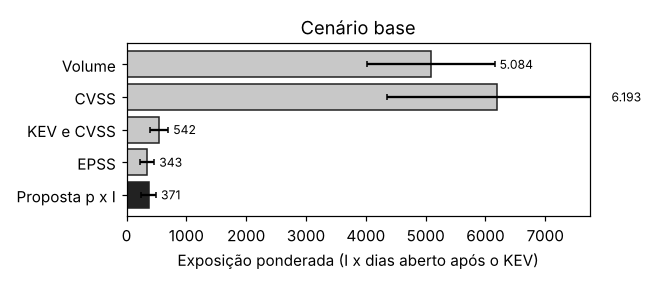

In [5]:
import matplotlib.pyplot as plt
ordem = ['volume', 'cvss', 'kev_cvss', 'epss', 'proposta']
fig, ax = plt.subplots(figsize=(6, 2.6))
vals = [c1[e]['exposicao'][0] for e in ordem]; ics = [c1[e]['exposicao'][1] for e in ordem]
ax.barh([nomes[e] for e in ordem], vals, xerr=ics, color=['#c8c8c8'] * 4 + ['#222222'], edgecolor='#222222', capsize=2)
ax.invert_yaxis(); ax.set_xlabel('Exposição ponderada (I x dias aberto após o KEV)'); ax.set_title('Cenário base')
for k, v in enumerate(vals):
    ax.text(v + ics[k] + 80, k, f'{v:,.0f}'.replace(',', '.'), va='center', fontsize=8)
ax.set_xlim(0, max(vals) * 1.25); fig.tight_layout(); plt.show()

## 4. Funções de risco com CVEs reais

Correlação de Kendall entre a fila ordenada por `p x I` e as demais funções, e a posição de cinco itens reais em cada fila.

In [6]:
f = r['funcoes']
print('Itens abertos em', f['t'], ':', f['n_itens'])
print('Kendall em relação a p x I:', {nomes.get(k, k): round(v, 2) for k, v in f['kendall_vs_produto'].items()})
ex = pd.DataFrame(f['exemplos'])[['cve', 'classe', 'p', 'I_media', 'nota', 'rank_proposta', 'rank_proposta_raiz', 'rank_aditiva', 'rank_cvss_impacto']]
ex.columns = ['CVE', 'ativo', 'p', 'I', 'CVSS', 'pos. p x I', 'pos. raiz', 'pos. soma', 'pos. CVSS x I']
print(); print(ex.round(4).to_string(index=False))

Itens abertos em 2025-11-01 : 91130
Kendall em relação a p x I: {'Raiz de p x I': 1.0, 'Soma ponderada': 0.63, 'CVSS x I': 0.18, 'CVSS': -0.0, 'EPSS': 0.23}

           CVE            ativo     p      I  CVSS  pos. p x I  pos. raiz  pos. soma  pos. CVSS x I
 CVE-2025-1974 servidor_exposto 0.987 0.9333   9.8         1.0        1.0        1.0           18.0
CVE-2025-49246 servidor_exposto 0.001 1.0000   4.3      8566.0     8566.0      468.0         3987.0
 CVE-2025-5356 servidor_exposto 0.001 1.0000   9.8      8782.0     8782.0      482.0            1.0
CVE-2025-47827          estacao 1.000 0.2333   NaN       237.0      237.0      211.0        67652.0
 CVE-2025-3248          estacao 1.000 0.1400   9.8       327.0      327.0      291.0        55462.0


## 5. Risco por hora de esforço: rodada de confirmação

A variante `p x I / esforço` foi definida depois dos primeiros resultados. Por isso a regra foi fixada e reavaliada em 30 inventários novos, com duas referências que isolam cada componente. Os valores vêm de `saida/confirmacao_esforco.json`, gerado por `confirmar_esforco.py`.

In [7]:
c = json.load(open('saida/confirmacao_esforco.json'))['cenarios']['C1']
rot = {'volume': 'Volume', 'kev_cvss': 'KEV e CVSS', 'epss': 'EPSS', 'proposta': 'p x I', 'proposta_hora': 'p x I / h', 'p_hora': 'p / h (sem o impacto)',
       'epss_hora': 'EPSS / h', 'proposta_epss': 'p x I (EPSS calibrado)', 'proposta_epss_hora': 'p x I / h (EPSS calibrado)'}
print(pd.DataFrame([{'estratégia': rot[e], 'exposição ponderada': round(v['exposicao'][0]), 'IC 95% (±)': round(v['exposicao'][1]),
                     'cobertura (%)': round(100 * v['cobertura'][0], 1), 'itens corrigidos': round(v['corrigidos'][0])} for e, v in c.items() if not e.startswith('_')]).sort_values('exposição ponderada').to_string(index=False))

                estratégia  exposição ponderada  IC 95% (±)  cobertura (%)  itens corrigidos
                 p x I / h                  117          44           91.8             90362
     p / h (sem o impacto)                  135          62           91.5             90699
p x I / h (EPSS calibrado)                  158          63           84.2             90122
    p x I (EPSS calibrado)                  263          96           68.5             61616
                      EPSS                  283         127           75.6             76612
                  EPSS / h                  295         142           80.9             90292
                     p x I                  321         114           64.2             60952
                KEV e CVSS                  400         131           67.2             76694
                    Volume                 3514         642           67.6             90807


## 6. Indicador de governança

Risco reduzido acumulado e risco residual médio por estratégia (`saida/indicadores_governanca.json`). O risco reduzido, sozinho, favorece quem corrige tarde; o risco residual acompanha a exposição.

In [8]:
g = json.load(open('saida/indicadores_governanca.json'))
print(pd.DataFrame([{'estratégia': rot[e], 'risco reduzido acumulado': round(v['risco_reduzido_acumulado'][0], 1), 'risco residual médio': round(v['risco_residual_medio'][0], 1)} for e, v in g.items()]).sort_values('risco residual médio').to_string(index=False))

estratégia  risco reduzido acumulado  risco residual médio
 p x I / h                      67.7                   6.0
     p x I                      81.8                  16.5
      EPSS                      84.9                  17.1
    Volume                      84.9                  19.7
KEV e CVSS                      79.0                  26.5
